# Guidance on MNIST: change the request, then the weight

**Estimated time: 60–75 minutes.** A class-conditional MNIST generator separates two ideas: *conditioning* (the
request is an input to the denoiser) and *guidance* (the weight w mixes the denoiser's two guesses). Complete
Parts 1–4.

Course convention: $x_0$ is noise, $x_1$ is data, and time runs from 0 to 1. The network $f_\theta(x_t, t, c)$
predicts the clean image. Its training hid the request on 10% of the examples, so label 10 is the "no request"
label; digits 0–9 are the available requests. The generator's weights stay fixed throughout. Grids show the first
ten outputs in sample order; the metrics use all N outputs.

The notebook is self-contained: the helper code (the U-Net with `cemb`, the sampler with $u + w(c - u)$, the
frozen digit classifier) is written by the setup cells below, and the weights are fetched once.

**Completed reference lab.** Outputs below use the supplied frozen `generator.pt`, not the network trained from scratch for the checkpoint. The checkpoint experiment and its 1,000-image FIDs are in [the report](../report/main.pdf). `python -m checkpoint.mnist_lab` executes the exercise cells and saves their actual outputs; the helper is loaded in memory.


## Setup
Run these cells once. They install the packages, write the helper code next to this notebook (you can leave the long cell collapsed), and fetch the model weights. If the kernel restarts, run them again.

In [ ]:
# @title Install the packages (already present in Colab and in the course environment)
%pip install --quiet torch numpy matplotlib


In [ ]:
%%writefile mnist_guidance_lab.py
"""Helpers for the MNIST guidance assignment: the class-conditional U-Net, the frozen digit classifier (an
evaluator, never a guide), the sampler with classifier-free guidance, and two diagnostics.

Course convention: x0 is noise at t = 0, x1 is data at t = 1, x_t = alpha_t x1 + sigma_t x0 on the cosine path
(alpha = sin(pi t / 2), sigma = cos(pi t / 2)), and the network predicts the clean image x1 from (x_t, t, label).
Label 10 means "no request"; the sampler mixes the two guesses as u + w (c - u).

The model and sampler are the course's speedrun/common.py and speedrun/sample.py, unchanged in behavior.
"""
from __future__ import annotations

import hashlib
import math
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


def alpha_sigma(t):
    """The cosine path: t = 0 is noise, t = 1 is data."""
    return torch.sin(t * torch.pi / 2), torch.cos(t * torch.pi / 2)


def alpha_sigma_dot(t):
    return (torch.pi / 2) * torch.cos(t * torch.pi / 2), -(torch.pi / 2) * torch.sin(t * torch.pi / 2)


# ------------------------------------------------------------------ the networks
class Evaluator(nn.Module):
    """A frozen MNIST classifier. It judges samples; it never steers them."""
    FEAT = 128

    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(), nn.MaxPool2d(2),
        )
        self.fc = nn.Linear(64 * 7 * 7, self.FEAT)
        self.head = nn.Linear(self.FEAT, 10)

    def features(self, x):
        return F.relu(self.fc(self.body(x).flatten(1)))

    def forward(self, x):
        f = self.features(x)
        return self.head(f), f


class Block(nn.Module):
    def __init__(self, cin, cout, emb):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.emb = nn.Linear(emb, cout)
        self.n1, self.n2 = nn.GroupNorm(8, cout), nn.GroupNorm(8, cout)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, e):
        h = F.silu(self.n1(self.c1(x)))
        h = h + self.emb(e)[:, :, None, None]        # the time embedding (and the request) enter every block here
        h = F.silu(self.n2(self.c2(h)))
        return h + self.skip(x)


class UNet(nn.Module):
    """Class-conditional denoiser: predicts the clean image x1 from (x_t, t, label). Label 10 = no request."""

    def __init__(self, ch=64, emb=256):
        super().__init__()
        self.temb = nn.Sequential(nn.Linear(1, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.cemb = nn.Embedding(11, emb)             # 10 digits + 1 "no request" label
        self.d1, self.d2, self.d3 = Block(1, ch, emb), Block(ch, ch * 2, emb), Block(ch * 2, ch * 2, emb)
        self.mid = Block(ch * 2, ch * 2, emb)
        self.u3 = Block(ch * 4, ch * 2, emb)
        self.u2 = Block(ch * 4, ch, emb)
        self.u1 = Block(ch * 2, ch, emb)
        self.out = nn.Conv2d(ch, 1, 3, padding=1)

    def forward(self, x, t, y):
        e = self.temb(t[:, None]) + self.cemb(y)     # the request is added to the time embedding
        h1 = self.d1(x, e)                           # 28 x 28
        h2 = self.d2(F.avg_pool2d(h1, 2), e)         # 14 x 14
        h3 = self.d3(F.avg_pool2d(h2, 2), e)         # 7 x 7
        m = self.mid(h3, e)
        u = self.u3(torch.cat([m, h3], 1), e)
        u = F.interpolate(u, size=h2.shape[-2:], mode="nearest")
        u = self.u2(torch.cat([u, h2], 1), e)
        u = F.interpolate(u, size=h1.shape[-2:], mode="nearest")
        u = self.u1(torch.cat([u, h1], 1), e)
        return self.out(u)


# ------------------------------------------------------------------ weights
def fetch(files: dict, folder=".") -> None:
    """Make sure each weight file is next to the notebook: files = {name: (url, sha256)}. Downloads what is
    missing or damaged and checks every file's hash."""
    for name, (url, digest) in files.items():
        path = Path(folder) / name
        if not path.exists() or hashlib.sha256(path.read_bytes()).hexdigest() != digest:
            print("downloading", name)
            urllib.request.urlretrieve(url, path)
        if hashlib.sha256(path.read_bytes()).hexdigest() != digest:
            raise RuntimeError(f"{name} does not match the course copy: delete it and run this cell again")


def load_models(folder=".", device="cpu"):
    """The class-conditional generator and the frozen evaluator, from generator.pt and evaluator.pt."""
    folder = Path(folder)
    ck = torch.load(folder / "generator.pt", map_location="cpu", weights_only=True)
    net = UNet(ch=ck["ch"]).to(device)
    net.load_state_dict(ck["state"])
    ck = torch.load(folder / "evaluator.pt", map_location="cpu", weights_only=True)
    evaluator = Evaluator().to(device)
    evaluator.load_state_dict(ck["state"])
    for model in (net, evaluator):
        model.eval().requires_grad_(False)
    return net, evaluator


# ------------------------------------------------------------------ sampling with guidance
@torch.no_grad()
def sample(net, n, labels, device, steps=16, w=2.0, eta=0.0, order="ddim", seed=0, batch=128):
    """n images for the requested labels. Guidance u + w (c - u): w = 0 ignores the request, w = 1 uses it as
    trained, w > 1 exaggerates it. Returns (images, network evaluations per image)."""
    if not isinstance(n, int) or n < 1 or not isinstance(steps, int) or steps < 1:
        raise ValueError("n and steps must be positive integers")
    if not isinstance(batch, int) or batch < 1:
        raise ValueError("batch must be a positive integer")
    if order not in ("ddim", "euler", "heun"):
        raise ValueError("order must be ddim, euler or heun")
    if not math.isfinite(w) or w < 0 or not math.isfinite(eta) or not 0 <= eta <= 1:
        raise ValueError("w must be nonnegative and eta must be in [0,1]")
    if eta and order != "ddim":
        raise ValueError("eta is supported only by DDIM; Euler/Heun are deterministic")
    labels = torch.as_tensor(labels, dtype=torch.long, device="cpu")
    if labels.shape != (n,) or (labels < 0).any() or (labels > 9).any():
        raise ValueError("supply n digit labels in [0,9]")
    g = torch.Generator(device="cpu").manual_seed(seed)       # one CPU noise bank: the same on every device
    initial = torch.randn(n, 1, 28, 28, generator=g)
    outs = []
    for i in range(0, n, batch):
        x, nfe = _sample_chunk(net, initial[i:i + batch], labels[i:i + batch], device, steps, w, eta, order,
                               seed + i + 1)
        outs.append(x.cpu())
    return torch.cat(outs), nfe


@torch.no_grad()
def _sample_chunk(net, initial, labels, device, steps, w, eta, order, noise_seed):
    g = torch.Generator(device="cpu").manual_seed(noise_seed)
    x, y = initial.to(device), labels.to(device)
    y_un = torch.full_like(y, 10)
    ts = torch.linspace(0, 1, steps + 1, device=device)
    nfe = 0

    def x1_hat(xt, t):
        nonlocal nfe
        tb = t.expand(xt.shape[0]).contiguous()
        if w in (0, 1):
            nfe += 1
            return net(xt, tb, y_un if w == 0 else y).clamp(-1, 1)
        out = net(torch.cat([xt, xt]), torch.cat([tb, tb]), torch.cat([y, y_un]))
        nfe += 2
        c, u = out.chunk(2)
        return (u + w * (c - u)).clamp(-1, 1)

    def velocity(xt, t):
        a, sg = alpha_sigma(t)
        x1 = x1_hat(xt, t)
        x0 = (xt - a * x1) / sg
        ad, sd = alpha_sigma_dot(t)
        return ad * x1 + sd * x0

    for i, (t, s) in enumerate(zip(ts[:-1], ts[1:])):
        if i == steps - 1:
            x = x1_hat(x, t)                          # the last step lands on the guess
        elif order in ("euler", "heun"):
            v = velocity(x, t)
            pred = x + (s - t) * v
            x = pred if order == "euler" else x + (s - t) * (v + velocity(pred, s)) / 2
        else:
            at, st = alpha_sigma(t)
            a_s, s_s = alpha_sigma(s)
            x1 = x1_hat(x, t)
            x0 = (x - at * x1) / st
            sig = eta * s_s / st * (1 - (at / a_s).square()).clamp_min(0).sqrt()
            keep = (s_s.square() - sig.square()).clamp_min(0).sqrt()
            x = a_s * x1 + keep * x0
            if eta:
                x += sig * torch.randn(x.shape, generator=g).to(device)
    return x.clamp(-1, 1), nfe


# ------------------------------------------------------------------ diagnostics and display
@torch.no_grad()
def classification(evaluator, x, y, device="cpu", bs=256):
    """Share of images the classifier reads as their requested digit, and its mean confidence in that digit."""
    ok, confidence = 0, 0.0
    for i in range(0, len(x), bs):
        logits, _ = evaluator(x[i:i + bs].to(device))
        labels = y[i:i + bs].to(device)
        ok += (logits.argmax(1) == labels).sum().item()
        confidence += logits.softmax(1).gather(1, labels[:, None]).sum().item()
    return ok / len(x), confidence / len(x)


def diagnostics(evaluator, images, labels, device="cpu") -> dict:
    """target_match: read as the requested digit. pixel_spread: mean per-pixel variance within each requested
    digit, a measure of variation (wanted or not), not of quality."""
    match, confidence = classification(evaluator, images, labels, device)
    spread = np.mean([float(images[labels == c].var(dim=0, unbiased=False).mean()) for c in labels.unique()])
    return dict(target_match=round(match, 3), confidence=round(confidence, 3), pixel_spread=round(float(spread), 4))


def grid(rows: dict, count: int = 10) -> None:
    """One row of images per entry of rows = {label: images}; the first `count` images of each."""
    fig, axes = plt.subplots(len(rows), count, figsize=(1.2 * count, 1.4 * len(rows)), squeeze=False)
    for r, (label, images) in enumerate(rows.items()):
        for j, ax in enumerate(axes[r]):
            ax.imshow(images[j, 0], cmap="gray", vmin=-1, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[r, 0].set_ylabel(label, rotation=0, ha="right", va="center")
    fig.tight_layout()
    plt.show()


In [1]:
# @title Get the model weights (downloaded once; skipped if the files are already here)
import hashlib, urllib.request
from pathlib import Path
FILES = {
    "generator.pt": (
        "https://drive.google.com/uc?export=download&id=1ET8_47MTKGwFr2hbG7eEyQwfLhqw3ql3",
        "ec413c1df3fdaf1321059a9fbde2265fa10c6499b6c7e0b9031b218e74f99bb6"
    ),
    "evaluator.pt": (
        "https://drive.google.com/uc?export=download&id=1RkocEim9ejow8n76WI0LGpNF18K5FxlW",
        "05e955d1c14856991785c408f9a818b5d887cdc2c5142d63eac134367f50b7fe"
    )
}
for name, (url, digest) in FILES.items():
    path = Path(name)
    if not path.exists() or hashlib.sha256(path.read_bytes()).hexdigest() != digest:
        print('downloading', name)
        urllib.request.urlretrieve(url, path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != digest:
        raise RuntimeError(f'{name} does not match the course copy: delete it and run this cell again')
print('weights ready:', ', '.join(FILES))


weights ready: generator.pt, evaluator.pt


In [2]:
import os, torch, numpy as np, matplotlib.pyplot as plt
import mnist_guidance_lab as mg
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = os.environ.get("LAB_DEVICE", "cpu")                                   # inference only; the CPU is enough ("cuda" or "mps" also work)
net, evaluator = mg.load_models(".", DEVICE)
def diagnostics(images, labels):
    return mg.diagnostics(evaluator, images, labels, DEVICE)
print("Models loaded. The generator is frozen; the classifier only judges samples.")

Models loaded. The generator is frozen; the classifier only judges samples.


## 1. Change the condition, keep the noise

Before running: with the same seed and $w=1$, will requesting 1 and 7 give the same image? Does a condition
prescribe every pixel? Each column below starts from the same noise across the two rows. No training image is
supplied during generation.

**Prediction and observation.** The same noise with requests 1 and 7 should give different identities; the label does not fix every pixel. In the recorded run (seed 7, 40 images, 16 steps), both requests reach 100% evaluator match, with pixel spreads 0.0935 and 0.1569. The first-ten grid below shows varied handwriting within each request.


1 network calls per image 16 {'target_match': 1.0, 'confidence': 0.996, 'pixel_spread': 0.0935}
7 network calls per image 16 {'target_match': 1.0, 'confidence': 0.99, 'pixel_spread': 0.1569}


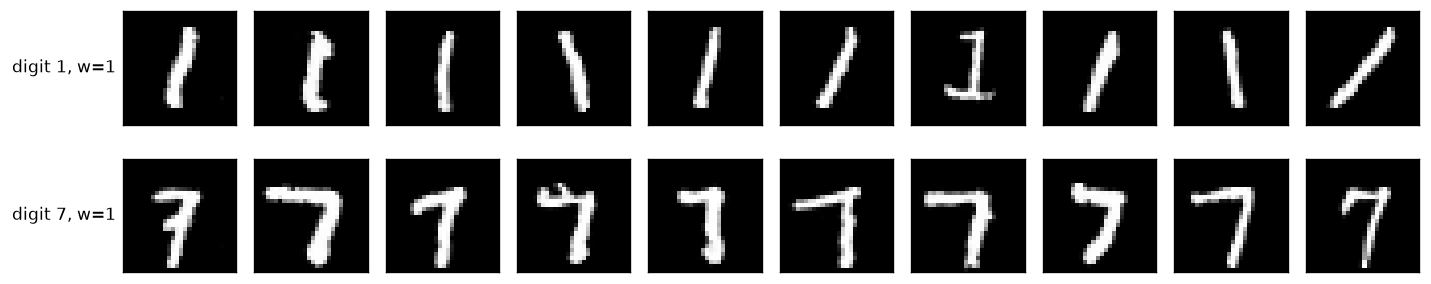

In [3]:
SEED = 7
N = 40
STEPS = 16
requests = [1, 7]  # Try two different digits.
rows = {}
for digit in requests:
    labels = torch.full((N,), digit)
    images, nfe = mg.sample(net, N, labels, DEVICE, steps=STEPS, w=1., seed=SEED)
    rows[f"digit {digit}, w=1"] = images
    print(digit, "network calls per image", nfe, diagnostics(images, labels))
mg.grid(rows)

## 2. Change guidance strength

The course convention is $f_w = f_\varnothing + w\,(f_c - f_\varnothing)$: $w=0$ is the "no request" guess,
$w=1$ the conditional guess, $w>1$ extrapolates past it. The sampler then clips the predicted clean image to
$[-1,1]$. A general $w$ needs two network calls per step; $w = 0$ or $1$ needs one. **Predict** how target matching
and variation will change before running.

The frozen digit classifier is only an evaluator. It never guides the sampler, and its match rate can miss
malformed digits. Pixel spread measures variation, wanted or not, and is not a quality score. These 40 samples
are too few for a distribution-level score; do not report FID here.

**Prediction and observation.** Stronger guidance may improve requested-digit matching but can exaggerate strokes or reduce variation; it need not improve quality. For target 7 at seed 7, $w=0,1,2,5$ give match rates 10%, 100%, 100%, 100% and spreads 0.2366, 0.1569, 0.1352, 0.1343. Matching already saturates at $w=1$. No FID is computed for these 40-image exercises.


w 0.0 network calls per image 16 {'target_match': 0.1, 'confidence': 0.1, 'pixel_spread': 0.2366}
w 1.0 network calls per image 16 {'target_match': 1.0, 'confidence': 0.99, 'pixel_spread': 0.1569}
w 2.0 network calls per image 32 {'target_match': 1.0, 'confidence': 1.0, 'pixel_spread': 0.1352}
w 5.0 network calls per image 32 {'target_match': 1.0, 'confidence': 1.0, 'pixel_spread': 0.1343}
Passed: w=0 ignores the requested digit; generator weights are frozen.


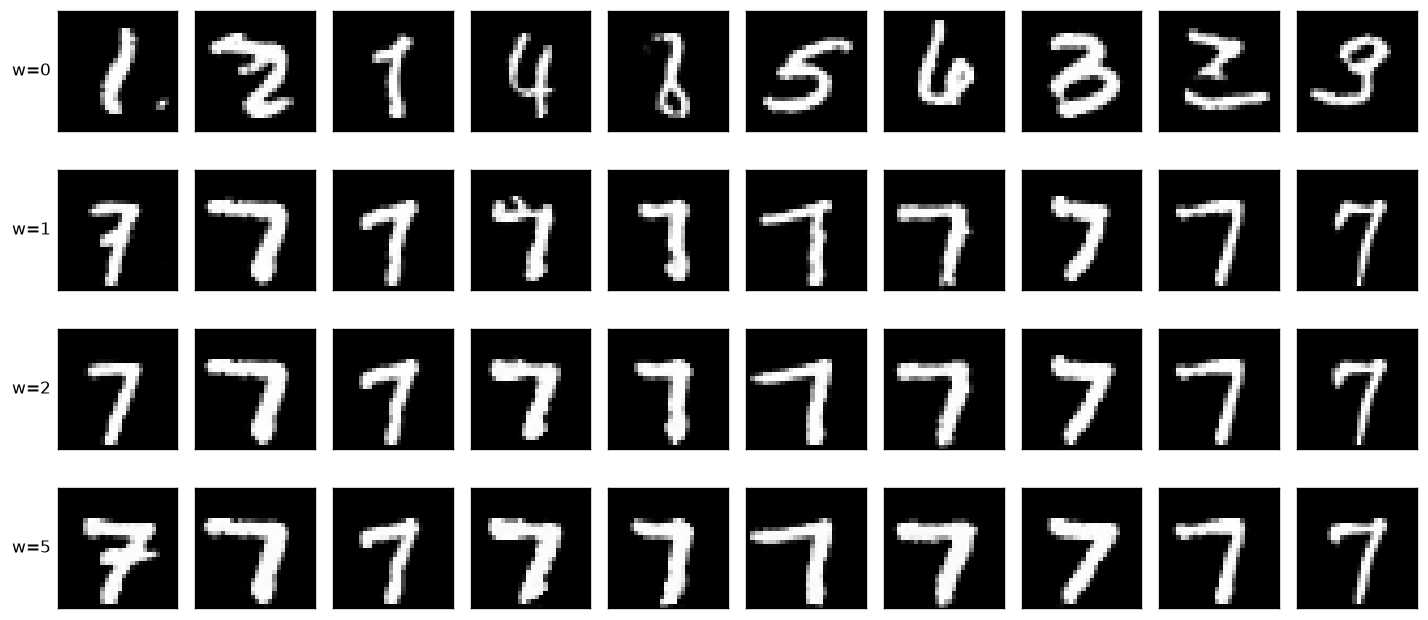

In [4]:
TARGET = 7
SCALES = [0., 1., 2., 5.]
labels = torch.full((N,), TARGET)
generated = {}
for w in SCALES:
    images, nfe = mg.sample(net, N, labels, DEVICE, steps=STEPS, w=w, seed=SEED)
    generated[f"w={w:g}"] = images
    print("w", w, "network calls per image", nfe, diagnostics(images, labels))
mg.grid(generated)

# With no request (w = 0) the requested digit must not matter, and the generator must be frozen.
null_a, _ = mg.sample(net, N, torch.zeros(N, dtype=torch.long), DEVICE, steps=STEPS, w=0., seed=SEED)
null_b, _ = mg.sample(net, N, torch.ones(N, dtype=torch.long), DEVICE, steps=STEPS, w=0., seed=SEED)
assert torch.equal(null_a, null_b)
assert all(not p.requires_grad for p in net.parameters())
print("Passed: w=0 ignores the requested digit; generator weights are frozen.")

## 3. Your controlled comparison

Repeat Parts 1–2 with another digit and another seed. Keep the checkpoint, the steps and the paired noise fixed
within each comparison. Make two labeled grids with their metric tables, then answer in 150–250 words:

1. Explain the difference between changing $c$ and changing $w$.
2. Does your grid support "larger $w$ always helps"? Include a failure or an ambiguous example rather than
   selecting only attractive digits.
3. Explain why target match and pixel spread together still do not establish image quality. Which samples need
   a human check?

**Answer (recorded CPU run; 199 words):**

Changing the condition c changes which digit is requested; changing w changes how strongly the conditional estimate is emphasized relative to the null estimate. A label does not specify handwriting or every pixel. With seed 19 and w=1, requests 3 and 8 achieve 100% and 95% evaluator match, respectively. Both use the same frozen generator, 40 initial noises, and 16 DDIM steps.

For target 3, match rates at w=0,1,2,5 are 5%, 100%, 100%, and 100%. Thus larger w does not always improve matching: it already saturates at one. Pixel spread falls from 0.2118 at w=1 to 0.1924 at w=2, then rises slightly to 0.1933 at w=5, so it is not strictly monotonic. In the condition grid, the sixth displayed eight has crowded, uneven loops and needs human inspection. The w=0 row also includes obvious non-threes, as expected when the request is ignored.

Target match is the judgment of one frozen classifier, which can confidently accept malformed digits. Pixel spread includes unwanted noise and distortion as well as meaningful handwriting variation. Neither measures realism or coverage of the real distribution. Ambiguous eights and exaggerated strokes therefore need a human check. Forty samples are too few for a distribution-level FID claim.

Condition comparison: seed=19, N=40, steps=16, w=1
digit  match  confidence  pixel_spread  calls/image
    3  1.000  0.997       0.2118        16
    8  0.950  0.948       0.2113        16
Guidance comparison: target=3, seed=19, N=40, steps=16
w      match  confidence  pixel_spread  calls/image
    0  0.050  0.066       0.2404        16
    1  1.000  0.997       0.2118        16
    2  1.000  1.000       0.1924        32
    5  1.000  1.000       0.1933        32


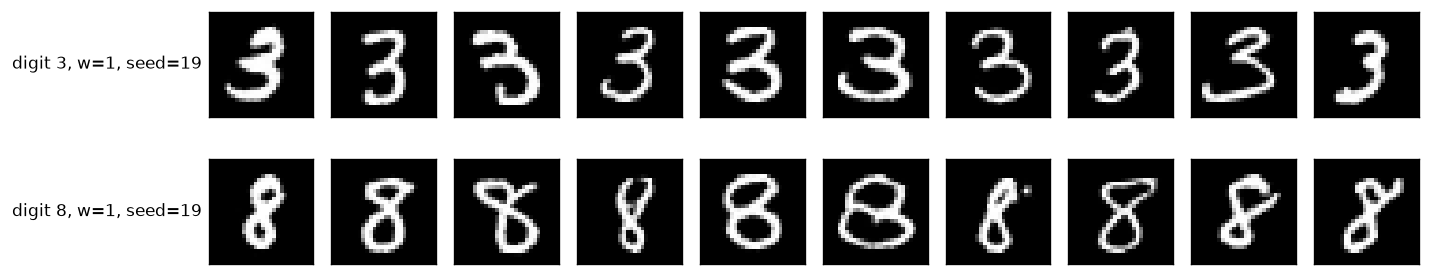

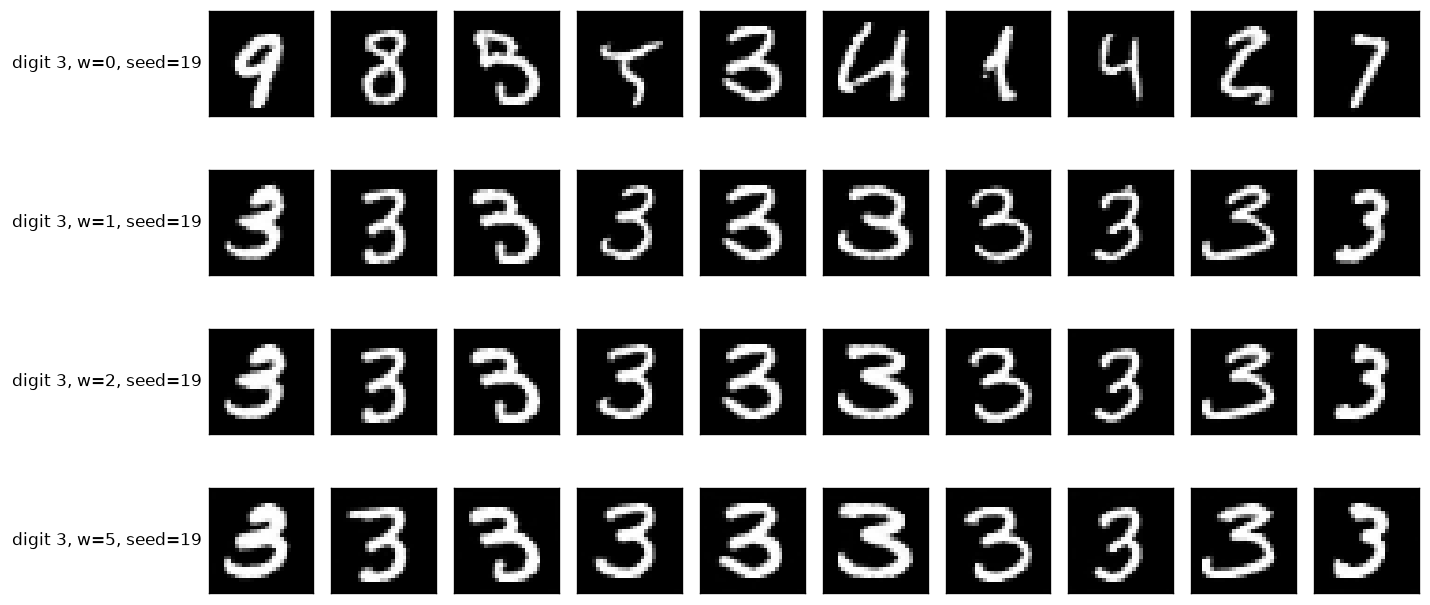

In [5]:
# Controlled comparison: new requests and seed, same frozen checkpoint and sampler.
COMPARE_SEED = 19
COMPARE_DIGITS = [3, 8]
COMPARE_TARGET = 3
comparison_condition_metrics, comparison_guidance_metrics = {}, {}
rows = {}
print(f"Condition comparison: seed={COMPARE_SEED}, N={N}, steps={STEPS}, w=1")
print("digit  match  confidence  pixel_spread  calls/image")
for digit in COMPARE_DIGITS:
    requested = torch.full((N,), digit)
    images, nfe = mg.sample(net, N, requested, DEVICE, steps=STEPS, w=1., seed=COMPARE_SEED)
    score = diagnostics(images, requested)
    comparison_condition_metrics[digit] = score
    rows[f"digit {digit}, w=1, seed={COMPARE_SEED}"] = images
    print(f"{digit:5d}  {score['target_match']:.3f}  {score['confidence']:.3f}       {score['pixel_spread']:.4f}        {nfe}")
mg.grid(rows)

rows = {}
print(f"Guidance comparison: target={COMPARE_TARGET}, seed={COMPARE_SEED}, N={N}, steps={STEPS}")
print("w      match  confidence  pixel_spread  calls/image")
for w in SCALES:
    requested = torch.full((N,), COMPARE_TARGET)
    images, nfe = mg.sample(net, N, requested, DEVICE, steps=STEPS, w=w, seed=COMPARE_SEED)
    score = diagnostics(images, requested)
    comparison_guidance_metrics[w] = score
    rows[f"digit {COMPARE_TARGET}, w={w:g}, seed={COMPARE_SEED}"] = images
    print(f"{w:5g}  {score['target_match']:.3f}  {score['confidence']:.3f}       {score['pixel_spread']:.4f}        {nfe}")
mg.grid(rows)


## 4. Connection to the code and the architecture

Answer briefly, using the slides and the `mnist_guidance_lab.py` cell above (the U-Net is at its top):

1. Locate `cemb` in `UNet.forward`. How does the requested digit enter this model, and where does the time enter?
2. Is this MNIST model pixel-space or latent-space? In latent diffusion, where would the encoder and decoder sit
   relative to the sampling loop?
3. What representation enters a DiT? Does replacing a U-Net by a transformer alone change the definition of
   guidance?
4. For a text prompt, an exact pose, and a masked local edit, name an appropriate input or interface from the
   lecture. Which requests can this digit-label model express without new training? Why can we not request a new
   class by using label 11?

**Answers:**

1. In `UNet.forward`, `e = self.temb(t[:, None]) + self.cemb(y)`. The digit selects one of 11 learned embeddings; time passes through an MLP. Their sum enters every residual block through its embedding projection and is added to the feature map.
2. This is pixel-space diffusion: the state is a noisy 28×28 image. In latent diffusion, an encoder maps training images to latents before denoiser training. At generation, sampling starts from latent noise, and a decoder maps the final latent to pixels after the loop; an encoder is not required inside an unconditional sampling loop.
3. The original DiT receives tokens made from patches of the noisy latent, together with position and time/condition information. Replacing the U-Net backbone with a transformer does not change CFG's unconditional-plus-weighted-difference definition.
4. A text prompt can enter through text-encoder embeddings and cross-attention; a pose map can condition a ControlNet-style spatial branch; a masked local edit uses an image-and-mask inpainting interface. A pose control encourages adherence rather than guaranteeing an exact pose. This model accepts only digit requests 0–9 or null label 10. It has no trained text, pose, or mask interface. Label 11 is outside its 11-entry embedding table, and a new class requires training rather than assigning an unused index.

Sources: the helper cell above; [latent diffusion](https://arxiv.org/abs/2112.10752), [DiT](https://arxiv.org/abs/2212.09748), and [ControlNet](https://arxiv.org/abs/2302.05543).

## Before the next class

Read Lipman et al., [Flow Matching for Generative Modeling](https://arxiv.org/abs/2210.02747), abstract and
Sections 2–3. Bring a sketch of one noise–data pair, its intermediate state and its velocity target.